# 7.1 Transformer
* 위치 인코딩

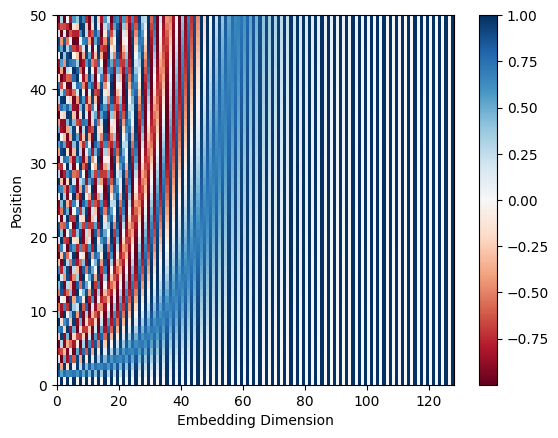

In [ ]:
import math
import torch
from torch import nn
from matplotlib import pyplot as plt

class PositionalEncoding(nn.Module):
  def __init__(self, d_model, max_len, dropout = 0.1):
    super().__init__()
    self.dropout = nn.Dropout(p = dropout)

    position = torch.arange(max_len).unsqueeze(1)
    div_term = torch.exp(
        torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
    )

    pe = torch.zeros(max_len, 1, d_model)
    pe[:, 0, 0::2] = torch.sin(position * div_term)
    pe[:, 0, 1::2] = torch.cos(position * div_term)
    self.register_buffer("pe", pe)

  def forward(self, x):
    x = x + self.pe[:, x.size(0)]
    return self.dropout(x)

encoding = PositionalEncoding(d_model = 128, max_len = 50)

plt.pcolormesh(encoding.pe.numpy().squeeze(), cmap = "RdBu")
plt.xlabel("Embedding Dimension")
plt.xlim((0, 128))
plt.ylabel("Position")
plt.colorbar()
plt.show()

# 모델 실습
### 토치 데이터 및 토치 텍스트 라이브러리 설치

In [ ]:
!pip install --upgrade torchtext torchdata portalocker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchtext]


In [ ]:
!python -m spacy download de_core_news_sm
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.6/14.6 MB 37.3 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('de_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 30.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


###  데이터세트 다운로드 및 전처리

In [ ]:
import urllib.request
import gzip
from collections import Counter
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import Vocab

def generate_tokens(text_iter, language):
  language_index = {SRC_LANGUAGE: 0, TGT_LANGUAGE: 1}

  for text in text_iter:
    yield token_transform[language](text[language_index[language]])

SRC_LANGUAGE = "de"
TGT_LANGUAGE = "en"
UNK_IDX, PAD_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3
special_symbols = ["<unk>", "<pad>", "<bos>", "<eos>"]

token_transform = {
    SRC_LANGUAGE: get_tokenizer("spacy", language="de_core_news_sm"),
    TGT_LANGUAGE: get_tokenizer("spacy", language="en_core_web_sm")
}
print("Token Transform")
print(token_transform)

def get_multi30k_train():
  base_url = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/"
  urllib.request.urlretrieve(base_url + "train.de.gz", "train.de.gz")
  urllib.request.urlretrieve(base_url + "train.en.gz", "train.en.gz")
  with gzip.open("train.de.gz", "rt", encoding="utf-8") as f_de, gzip.open("train.en.gz", "rt", encoding="utf-8") as f_en:
    return list(zip([l.strip() for l in f_de], [l.strip() for l in f_en]))

train_data = get_multi30k_train()

vocab_transform = {}
for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
  counter = Counter()
  for tokens in generate_tokens(train_data, language):
    counter.update(tokens)
  vocab_transform[language] = Vocab(
      counter,
      min_freq=1,
      specials=special_symbols
  )

print("Vocab Transform")
print(vocab_transform)

Token Transform
{'de': functools.partial(<function _spacy_tokenize at 0x7f4a7efef380>, spacy=<spacy.lang.de.German object at 0x7f4a733ae3c0>), 'en': functools.partial(<function _spacy_tokenize at 0x7f4a7efef380>, spacy=<spacy.lang.en.English object at 0x7f4a733ac590>)}
Vocab Transform
{'de': <torchtext.vocab.Vocab object at 0x7f4a733af770>, 'en': <torchtext.vocab.Vocab object at 0x7f4b5d7b6710>}


* 독일어 말뭉치(de_core_news_sm)와 영어 말뭉치(en_core_web_sm)에 대해 각각 토크나이저와 어휘 사전 생성
* get_tokenizer(): 사용자가 지정한 토크나이저를 불러오는 유틸리티 함수. spaCy 라이브러리로 사전 학습된 모델 가져옴.이를 token_transform 변수에 저장
* vocab_transform: 토큰을 인덱스로 변환시키는 함수 저장.

   Multi30k 데이터세트 활용해 (독일어, 영어)의 튜플 형식으로 데이터 불러옴
* build_vocab_from_iterator() & generate_tokens(): 언어별 어휘 사전 생성
* build_vocab_from_iteraotr(): 생성된 토큰 이용해 단어 집합 생성
* min_freq:최소 빈도. 토큰화된 단어들의 최소 빈도수 지정
* specials: 복수 토큰. 트랜스포머에 활용하는 특수 토큰 지정.

    special_first 매개변수가 참인 경우 특수 토큰을 단어 집합의 맨 앞에 추가함
* set_default_index 메서드: 인덱스의 기본값 설정. 어휘 사전에 없는 토큰인 <unk> 인덱스를 할당함



### 트랜스포머 모델 구성

In [ ]:
import math
import torch
from torch import nn

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        position = torch.arange(max_len).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model)
        )
        pe = torch.zeros(max_len, 1, d_model)
        pe[:, 0, 0::2] = torch.sin(position * div_term)
        pe[:, 0, 1::2] = torch.cos(position * div_term)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[:x.size(0)]
        return self.dropout(x)

class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size, emb_size):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_size)
        self.emb_size = emb_size

    def forward(self, tokens):
        return self.embedding(tokens.long()) * math.sqrt(self.emb_size)

class Seq2SeqTransformer(nn.Module):
    def __init__(
        self,
        num_encoder_layers,
        num_decoder_layers,
        emb_size,
        max_len,
        nhead,
        src_vocab_size,
        tgt_vocab_size,
        dim_feedforward,
        dropout=0.1
    ):
        super().__init__()
        self.src_tok_emb = TokenEmbedding(src_vocab_size, emb_size)
        self.tgt_tok_emb = TokenEmbedding(tgt_vocab_size, emb_size)
        self.positional_encoding = PositionalEncoding(
            d_model=emb_size, max_len=max_len, dropout=dropout
        )
        self.transformer = nn.Transformer(
            d_model=emb_size,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout
        )
        self.generator = nn.Linear(emb_size, tgt_vocab_size)

    def forward(
        self,
        src,
        tgt,
        src_mask,
        tgt_mask,
        src_padding_mask,
        tgt_padding_mask,
        memory_key_padding_mask
    ):
        src_emb = self.positional_encoding(self.src_tok_emb(src))
        tgt_emb = self.positional_encoding(self.tgt_tok_emb(tgt))
        outs = self.transformer(
            src=src_emb,
            tgt=tgt_emb,
            src_mask=src_mask,
            tgt_mask=tgt_mask,
            memory_mask=None,
            src_key_padding_mask=src_padding_mask,
            tgt_key_padding_mask=tgt_padding_mask,
            memory_key_padding_mask=memory_key_padding_mask
        )
        return self.generator(outs)

    def encode(self, src, src_mask):
        return self.transformer.encoder(
            self.positional_encoding(self.src_tok_emb(src)), src_mask
        )

    def decode(self, tgt, memory, tgt_mask):
        return self.transformer.decoder(
            self.positional_encoding(self.tgt_tok_emb(tgt)), memory, tgt_mask
        )

* Seq2SeqTransformer 클래스: TokenEmbdding 클래스. 소스 데이터와 입력 데이터를 입력 임베딩으로 변환하여 src_tok_emb와 tgt_tok_emb 생성.

    -> 소스와 타깃 데이터의 어휘 사전 크기 입력받아 트랜스포머 임베딩 크기로 변환함
* self.transformer(트랜스포머 블록): 파이토치에서 제공하는 트랜스포머 클래스 적용.

  트랜스포머 인코더와 디코더는 encoder_layers 변수의 값으로 구성됨
* 순방향 메서드 마지막에 적용되는 generator: 마지막 트랜스포머 디코더 블록에서 산출되는 벡터를 선형 변환해 어휘 사전에 대한 로짓(logit) 생성

### 트랜스포머 클래스

In [ ]:
transformer = torch.nn.Transformer(
    d_model=512,
    nhead=8,
    num_encoder_layers=6,
    num_decoder_layers=6,
    dim_feedforward=2048,
    dropout=0.1,
    activation=torch.nn.functional.relu,
    layer_norm_eps=1e-05
)

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/transformer.py:145: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  self.encoder = TransformerEncoder(


* d_model: 임베딩 차원. 트랜스포머 모델의 입력과 출력 차원의 크기 = 임베딩 차원 크기
* nhead: 헤드. 멀티 헤드 어텐션의 헤드 개수.
어텐션 수행하는 방법 결정함. 헤드 개수 많을수록 모델 병렬 처리 능력 증가함.

    단 헤드 개수 증가할수록 모델 매개변수 수도 증가함
* num_encoder_layers: 인코더 계층 개수 & num_decoder_layers: 디코더 계층 개수.

    복잡도와 성능에 영향.
계층 개수 많을수록 복잡한 문제 해결 가능 but 너무 많을 경우 과대적합될 수 O
* dim_feedforward: 순방향 신경망 은닉층 크기.

    트랜스포머 계층의 각 입력 위치에 독립적으로 적용. 복잡도와 성능에 영향
* dropout: 인코더와 디코더 계층에 적용되는 드롭아웃 비율
* activation: 순방향 신경망에 적용되는 활성화 함수. 파이토치 함수 형태로 입력 가능
* layer_norm_eps: 계층 정규화 입실론. 계층 정규화 수행 시 분모에 더해지는 입실론 값

### 트랜스포머 순방향 메서드

In [ ]:
src = torch.rand((10, 32, 512))
tgt = torch.rand((20, 32, 512))

output = transformer.forward(
    src,
    tgt,
    src_mask=None,
    tgt_mask=None,
    memory_mask=None,
    src_key_padding_mask=None,
    tgt_key_padding_mask=None,
    memory_key_padding_mask=None
)

* src(소스) & tgt(타깃): 인코더와 디코더에 대한 시퀀스.

   [소스(타깃) 시퀀스 길이, 배치 크기, 임베딩 차원] 형태의 데이터를 입력받음
* src_mask, tgt_mask: 소스와 타깃 시퀀스의 마스크.

   [소스(타깃) 시퀀스 길이, 시퀀스 길이] 형태의 데이터 입력받음

    if 마스크 값 = 0 -> 해당 위치에서는 모든 입력 단어가 동일한 가중치 갖고 어텐션 수행됨

   if 마스크 = 1 -> 모든 입력 단어의 가중치가 0으로 설정돼 어텐션 연산 수행되지 않음

   if 마스크 = -inf -> 해당 위치에서는 어텐션 연산 결과에 0으로 가중치가 부여돼 마스킹된 위치 정보 무시

   if 마스크 = +inf -> 모든 입력 단어에 무한대 가중치 부여되어 어텐션 결과가 해당 위치에 대한 정보만으로 구성됨(특정 단어나 위치에 모델이 특별한 관심 가지도록 할 때만 사용)
* memory_mask: 인코더 출력의 마스크.

   [타깃 시퀀스 길이, 소스 시퀀스 길이] 형태

   if 메모리 마스크 = 0 -> 해당 위치에서는 어텐션 연산 수행 X
* key_padding_mask: 소스, 타깃, 메모리 키 패딩 마스크. 메모리 키 패딩 마스크는 소스 키 패딩 마스크와 동일한 형태 데이터 입력 받음
   
  [배치 크기, 소스(타깃) 시퀀스 길이]

  키 패딩 마스크: 입력 시퀀스에서 패딩 토큰이 위치한 부분을 가리키는 이진 마스크. 패딩 토큰이 실제 의미를 가지지 않은 것으로 간주 -> 해당 위치의 어텐션 연산 결과에 대한 가중치 0으로 만듦

* 순방향 메서드: 인스턴스의 설정과 입력 시퀀스 통해 타깃 시퀀스의 임베딩 텐서를 반환하여 [타깃 시퀀스 길이, 배치 크기, 임베딩 차원] 반환
   
   현재 클래스에서는 어휘 사전에 대한 로짓 생성하므로 임베딩 차원이 타깃 데이터의 어휘 사전 크기로 변경됨

### 트랜스포머 모델 구조

In [ ]:
from torch import optim

BATCH_SIZE = 128
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = Seq2SeqTransformer(
    num_encoder_layers=3,
    num_decoder_layers=3,
    emb_size=512,
    max_len=512,
    nhead=8,
    src_vocab_size=len(vocab_transform[SRC_LANGUAGE]),
    tgt_vocab_size=len(vocab_transform[TGT_LANGUAGE]),
    dim_feedforward=512
).to(DEVICE)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX).to(DEVICE)
optimizer = optim.Adam(model.parameters())

for main_name, main_module in model.named_children():
  print(main_name)
  for sub_name, sub_module in main_module.named_children():
    print("└", sub_name)
    for sub_sub_name, sub_sub_module in sub_module.named_children():
      print("|  └", sub_sub_name)
      for ssub_sub_name, ssub_sub_module in sub_sub_module.named_children():
        print("|  |  └", ssub_sub_name)

src_tok_emb
└ embedding
tgt_tok_emb
└ embedding
positional_encoding
└ dropout
transformer
└ encoder
|  └ layers
|  |  └ 0
|  |  └ 1
|  |  └ 2
|  └ norm
└ decoder
|  └ layers
|  |  └ 0
|  |  └ 1
|  |  └ 2
|  └ norm
generator


* Seq2SeqTransformer 클래스: 입력 임베딩(src_tok_emb, tgt_tok_emb), 위치 인코딩(positional_encoding), 트랜스포머 블록(transformer), 로짓 생성(generaotr)로 구성됨.

    인코더와 디코더 각각 (0, 1, 2) 계층으로 구성
* 실습에서 손실함수로 교차 엔트로피 함수 적용.
   
   무시되는 색인(ignore_index) 값을 패딩 토큰(PAD_IDX) 할당해 모델이 학습하는 동안 무시해야 할 클래스 레이블 지정(패딩 토큰은 모델 학습에 사용 X)

### 배치 데이터 생성

In [ ]:
import urllib.request
import gzip
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

def sequential_transform(*transforms):
  def func(txt_input):
    for transform in transforms:
      txt_input = transform(txt_input)
    return txt_input
  return func

def input_transform(token_ids):
  return torch.cat(
      (torch.tensor([BOS_IDX]), torch.tensor(token_ids), torch.tensor([EOS_IDX]))
  )

def collator(batch):
  src_batch, tgt_batch = [], []
  for src_sample, tgt_sample in batch:
    src_batch.append(text_transform[SRC_LANGUAGE](src_sample.rstrip("\n")))
    tgt_batch.append(text_transform[TGT_LANGUAGE](tgt_sample.rstrip("\n")))

  tgt_batch = pad_sequence(tgt_batch, padding_value=PAD_IDX)
  src_batch = pad_sequence(src_batch, padding_value=PAD_IDX)
  return src_batch, tgt_batch

text_transform = {}
for language in [SRC_LANGUAGE, TGT_LANGUAGE]:
  text_transform[language] = sequential_transform(
      token_transform[language],
      lambda tokens, lang=language: [vocab_transform[lang][token] for token in tokens],
      input_transform
  )

def get_multi30k_valid():
  base_url = "https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/"
  urllib.request.urlretrieve(base_url + "val.de.gz", "val.de.gz")
  urllib.request.urlretrieve(base_url + "val.en.gz", "val.en.gz")
  with gzip.open("val.de.gz", "rt", encoding="utf-8") as f_de, gzip.open("val.en.gz", "rt", encoding="utf-8") as f_en:
    return list(zip([l.strip() for l in f_de], [l.strip() for l in f_en]))

data_iter = get_multi30k_valid()
dataloader = DataLoader(data_iter, batch_size=BATCH_SIZE, collate_fn=collator)
source_tensor, target_tensor = next(iter(dataloader))

print("(source, target):")
print(next(iter(data_iter)))
print("source_batch:", source_tensor.shape)
print(source_tensor)
print("target_batch:", target_tensor.shape)
print(target_tensor)

(source, target):
('Eine Gruppe von Männern lädt Baumwolle auf einen Lastwagen', 'A group of men are loading cotton onto a truck')
source_batch: torch.Size([35, 128])
tensor([[   2,    2,    2,  ...,    2,    2,    2],
        [  14,    5,    5,  ...,    5,   21,    5],
        [  38,   12,   35,  ...,   12, 1750,   69],
        ...,
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1]])
target_batch: torch.Size([30, 128])
tensor([[   2,    2,    2,  ...,    2,    2,    2],
        [   6,    6,    6,  ...,  250,   19,    6],
        [  39,   12,   35,  ...,   12, 3254,   61],
        ...,
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1],
        [   1,    1,    1,  ...,    1,    1,    1]])


* sequential_transforms(): 여러 전처리 함수를 인자로 받아 차례로 적용하는 함수 반환. 예제에서는 세 종류 전처리 수행

   1. token_transform: 문장 토큰화
   2. vocab_transform: 각 토큰 인덱스화
   3. input_transform: 인덱스화된 토큰에 문장의 시작 BOS_IDX(2)와 끝 EOS_IDX(3)을 알리는 특수 토큰 할당
* data_iter 변수에 (독일어, 영어) 형태로 구성된 Multi30k 텍스트 데이터세트를 불러옴.
   
   이 데이터세트를 데이터로더에 적용하며, 집합 함수는 collator 함수 적용
* collator(): 배치 단위로 데이터 처리
* rstrip("\n") 함수로 문자열 끝에 있는 개행 문자 (\n) 제거
* text_transform 변수에 저장된 sequential_transforms 함수 적용
* pad_sequence(): 패딩 시퀀스 함수. 소스와 타깃 시퀀스 패딩. 동일한 길이를 가지도록 시퀀스 뒤쪽에 PAD_IDX(1)로 채워진 패딩 토큰 추가

    -> 이 데이터로더는 (패딩이 적용된 소스, 패딩이 적용된 타깃) 튜플을 반환함. 출력되는 배치 데이터 차원은 [35, 128]과 [30, 128]로, [소스(타깃) 시퀀스 길이, 배치 크기] 의미
   

### 어텐션 마스크 생성

In [ ]:
def generate_square_subsequent_mask(s):
  mask = (torch.triu(torch.ones((s, s), device=DEVICE)) == 1).transpose(0, 1)
  mask = (
      mask.float()
      .masked_fill(mask == 0, float("-inf"))
      .masked_fill(mask == 1, float(0.0))
  )
  return mask

def create_mask(src,tgt):
  src_seq_len = src.shape[0]
  tgt_seq_len = tgt.shape[0]

  tgt_mask = generate_square_subsequent_mask(tgt_seq_len)
  src_mask = torch.zeros((src_seq_len, src_seq_len), device=DEVICE).type(torch.bool)

  src_padding_mask = (src == PAD_IDX).transpose(0, 1)
  tgt_padding_mask = (tgt == PAD_IDX).transpose(0, 1)
  return src_mask, tgt_mask, src_padding_mask, tgt_padding_mask

target_input = target_tensor[:-1, :]
target_out = target_tensor[1:, :]

source_mask, target_mask, source_padding_mask, target_padding_mask = create_mask(
    source_tensor, target_input
)

print("source_mask:", source_mask.shape)
print(source_mask)
print("target_mask:", target_mask.shape)
print(target_mask)
print("source_padding_mask:", source_padding_mask.shape)
print(source_padding_mask)
print("target_padding_mask:", target_padding_mask.shape)
print(target_padding_mask)

source_mask: torch.Size([35, 35])
tensor([[False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        ...,
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False],
        [False, False, False,  ..., False, False, False]], device='cuda:0')
target_mask: torch.Size([29, 29])
tensor([[0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf, -inf, -inf],
        [0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf, -inf, -inf],
        [0., 0., 0., -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf, -inf,
         -inf, -inf, -inf,

* 위 셀은 트랜스포머 모델에서 사용되는 마스크를 생성하는 함수와 두 시퀀스의 패딩 마스크를 생성하는 함수로 구성
* generate_square_subsequent_mask: 마스크를 생성하는 함수
    
    입력으로 정수 s를 받아 sxs 크기의 마스크 생성
    * torch.ones(): 1로 채워진 행렬 만듦 -> torch.triu(): 상삼각행렬(Upper traingular matrix) 생성 -> transpose(): 행렬 전치
    * 마스크 텐서에서 0인 값 -> -inf, 1 -> 0.0
    (0.0 = 셀프 어텐션에 참조되는 시퀀스, -inf = 셀프 어텐션 계산 과정에서 어텐션 스코어가 0으로 수렴하기 때문에 해당 타깃 입력 시퀀스를 제외시키는 역할)
* create_mask: 패딩 마스크 생성. 시퀀스 입력받아 길이 계산하고 마스크 생성 함수로 타깃 시퀀스의 마스크 생성
    * 소스 마스크: 소스 시퀀스 길이의 크기로 채워진 행렬 생성
    * 패딩 마스크: 각 시퀀스에 대해 패딩 토큰의 위치를 갖고 transpose 함수로 전치
    1. (패딩 마스크 생성 전) target_input, target_out: 토큰 순서를 한 칸 시프트하여 이전 토큰들이 주어졌을 때 다음 토큰 예측하게 함
    2. 패딩 마스크 생성 함수로 source_tensor(시퀀스 입력값) & target_input(타깃 시퀀스 입력값) 전달해 4개의 텐서를 생성
* source_mask: 셀프 어텐션 과정에서 참조되는 소스 데이터의 시퀀스 범위.
   
    False인 위치는 셀프 어텐션에 참조되는 토큰이 됨
    True인 위치는 어텐션에서 제외되는 토큰이 됨
    -> 출력 결과 확인해보면 소스 데이터는 모든 시퀀스를 대상으로 셀프 어텐션이 수행됨
* target_mask: [쿼리 시퀀스 길이, 키 시퀀스 길이]. i번째 쿼리 벡터는 i+1 이상의 키 벡터에 대해 어텐션 연산 수행 X

    -> 모델이 현재 예측하고자 하는 위치 이전의 토큰들만 참고하게 제한함으로써, 모델이 미래 시점의 정보를 사용하지 않게 해 현재 시점에 영향 X
* source_padding_mask & target_padding_mask: 소스(타깃) 배치 데이터에서 텍스트 토큰이 존재하는지 여부 나타냄.

    False 경우 해당 토큰 인덱스 존재
    True 경우 해당 토큰 인덱스가 패딩 토큰으로 채워져 있음

### 모델 학습 및 평가

In [ ]:
def run(model, optimizer, criterion, split):
  model.train() if split == "train" else model.eval()
  current_iter = train_data if split == "train" else data_iter
  dataloader = DataLoader(current_iter, batch_size=BATCH_SIZE, collate_fn=collator)

  losses = 0
  for source_batch, target_batch in dataloader:
    source_batch = source_batch.to(DEVICE)
    target_batch = target_batch.to(DEVICE)

    target_input = target_batch[:-1, :]
    target_output = target_batch[1:, :]

    src_mask, tgt_mask, src_padding_mask, tgt_padding_mask = create_mask(
        source_batch, target_input
    )

    logits = model(
        src=source_batch,
        tgt=target_input,
        src_mask=src_mask,
        tgt_mask=tgt_mask,
        src_padding_mask=src_padding_mask,
        tgt_padding_mask=tgt_padding_mask,
        memory_key_padding_mask=src_padding_mask,
    )

    optimizer.zero_grad()
    loss = criterion(logits.reshape(-1, logits.shape[-1]), target_output.reshape(-1))
    if split == "train":
      loss.backward()
      optimizer.step()
    losses += loss.item()

  return losses / len(list(dataloader))

for epoch in range(5):
  train_loss = run(model, optimizer, criterion, "train")
  val_loss = run(model, optimizer, criterion, "valid")
  print(f"Epoch: {epoch+1}, Train loss: {train_loss:.3f}, Val loss: {val_loss:.3f}")

/usr/local/lib/python3.13/dist-packages/torch/nn/modules/activation.py:1337: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = F._canonical_mask(


Epoch: 1, Train loss: 4.690, Val loss: 3.935
Epoch: 2, Train loss: 3.751, Val loss: 3.638
Epoch: 3, Train loss: 3.507, Val loss: 3.576
Epoch: 4, Train loss: 3.375, Val loss: 3.561
Epoch: 5, Train loss: 3.272, Val loss: 3.535


* run(): 모델 학습 및 평가를 위한 함수. 소스와 타깃 데이터를 입력받아 collator로 문장들을 토큰화하고 인덱스로 변환
* create_mask(): 트랜스포머 모델에 필요한 입력 패딩 마스크(src_padding_mask, tgt_padding_mask)와 어텐션 마스크(src_mask, tgt_mask) 생성
-> 타깃 시퀀스의 i번째까지 토큰이 주어졌을 떄 i+1번째 토큰을 예측하는데 활용됨
* 출력 결과 보면 5 에폭까지 모델 학습했을 때 Train_loss와 Val_loss 모두 감소해 모델이 학습됨을 확인 가능

### 트랜스포머 모델 번역 결과

In [ ]:
def greedy_decode(model, source_tensor, source_mask, max_len, start_symbol):
  source_tensor = source_tensor.to(DEVICE)
  source_mask = source_mask.to(DEVICE)

  memory = model.encode(source_tensor, source_mask)
  ys = torch.ones(1,1).fill_(start_symbol).type(torch.long).to(DEVICE)
  for i in range(max_len - 1):
    memory = memory.to(DEVICE)
    target_mask = generate_square_subsequent_mask(ys.size(0))
    target_mask = target_mask.type(torch.bool).to(DEVICE)

    out = model.decode(ys, memory, target_mask)
    out = out.transpose(0, 1)
    prob = model.generator(out[:, -1])
    _, next_word = torch.max(prob, dim=1)
    next_word = next_word.item()

    ys = torch.cat(
        [ys, torch.ones(1,1).type_as(source_tensor.data).fill_(next_word)], dim=0
    )
    if next_word == EOS_IDX:
      break
  return ys

def translate(model, source_sentence):
  model.eval()
  source_tensor = text_transform[SRC_LANGUAGE](source_sentence).view(-1,1)
  num_tokens = source_tensor.shape[0]
  src_mask = (torch.zeros(num_tokens, num_tokens)).type(torch.bool)
  tgt_tokens = gready_decode(
      model, source_tensor, src_mask, max_len=num_tokens + 5, start_symbol=BOS_IDX
  ).flatten()
  output = [vocab_transform[TGT_LANGUAGE].itos[idx] for idx in tgt_tokens.cpu().numpy()][1:-1]
  return " ".join(output)

output_oov = translate(model, "Eine Gruppe von Menschen steht vor einem Iglu .")
output = translate(model, "Eine Gruppe von Menschen steht vor einem Gebäude .")
print(output_oov)
print(output)

A group of people are sitting on a bench .
A group of people are sitting on a bench .


* 모델 번역 방식: 그리드 디코딩(Greedy decoding): 디코더 네트워크가 생성한 확률 분포에서 가장 높은 확률을 가지는 단어를 선택하는 방법. 현재 시점에서 가장 확률이 높은 단어를 선택하여 디코딩 진행
* 모델 추론 방식: 디코더에 참조되는 마지막 인코더 트랜스포머 블록의 벡터(memory), 타깃 데이터의 입력 텐서(ys), 타깃 마스크(target_mask) 사용
    * memory 텐서 생성 위해 소스 문장을 토큰 인덱스로 표현한 source_tensor 생성, source_mask는 소스 문장에서 모든 토큰이 어텐션이 될 수 있게 0으로 설정
* model.encode 메서드에 source_tensor, source_mask 입력으로 넣어 소슴 누장에 대한 인코딩 수행해 마지막 인코더 트랜스포머 블록의 벡터 추출
* model.decode 메서드에서 생성된 out[토큰 개수, 배치 크기, 확률] 형태.

    이 값을 transpose 함수를 이용해 [배치 크기, 토큰 개수, 확률] 형태로 변환

    -> 텐서를 슬라이싱해 [배치 크기, 확률] 형태로 만듦

    -> 어휘 사전에서 가장 확률이 높은 토큰 인덱스를 찾음

    -> max_len 이전 또는 EOS_IDX 예측할때까지 반복

    -> 최종 예측된 토큰 시퀀스를 반환
* max_len: num_tokens+5로 구성.
    * num_toekns: 소스 문장의 토큰 개수
    * 보통 생성된 문장 길이 > 소스 문장 길이인 경우가 많아 5를 더함
* greedy_decode(): 현재까지 예측된 토큰들을 이요해 다음 토큰 예측. 이때 가장 높은 확률을 가지는 단어를 선택하여 다음 토큰으로 예측
* 마지막으로 예측된 토큰 인덱스를 어휘 사전의 lookup_tokens() 통해 텍스트로 변환
* 후처리로 <bos>, <eos> 토큰은 슬라이싱[1:-1]로 제거


* 번역 결과를 보면 모델이 입력 문장의 의미를 정확하게 파악하지 못 하고 잘못된 번역 결과를 도출함. 더 정확한 번역 위해 더 많은 학습 데이터를 사용하거나 모델의 구조 또는 하이퍼파라미터 등을 변경해 모델 성능 지속적으로 모니터링, 개선해야함

# 7.2 GPT
## 모델 실습
### 문장 생성을 위한 GPT-2 모델의 구조


In [1]:
from transformers import GPT2LMHeadModel

model = GPT2LMHeadModel.from_pretrained(
    pretrained_model_name_or_path="gpt2"
)

for main_name, main_module in model.named_children():
    print(main_name)
    for sub_name, sub_module in main_module.named_children():
        print("ㄴ", sub_name)
        for ssub_name, ssub_module in sub_module.named_children():
            print("│ ㄴ", ssub_name)
            for sssub_name, sssub_module in ssub_module.named_children():
                print("│ │ ㄴ", sssub_name)

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

transformer
ㄴ wte
ㄴ wpe
ㄴ drop
ㄴ h
│ ㄴ 0
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 1
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 2
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 3
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 4
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 5
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 6
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 7
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 8
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 9
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 10
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
│ ㄴ 11
│ │ ㄴ ln_1
│ │ ㄴ attn
│ │ ㄴ ln_2
│ │ ㄴ mlp
ㄴ ln_f
lm_head


* GPT-2를 이용한 문장 생성

In [2]:
from transformers import pipeline

generator = pipeline(task="text-generation", model="gpt2")

outputs = generator(
    text_inputs="Machine learning is",
    max_length=20,
    num_return_sequences=3,
    pad_token_id=generator.tokenizer.eos_token_id
)

print(outputs)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'generated_text': 'Machine learning is a very useful tool for understanding the world around us. This is why research into how'}, {'generated_text': 'Machine learning is still quite young, and the current paradigm is largely confined to the academic world, with'}, {'generated_text': 'Machine learning is the process of learning new things and adapting them to the new environment. In fact,'}]


* CoLA 데이터세트 불러오기

In [4]:
!pip install --upgrade torchtext torchdata portalocker

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torchtext]


In [6]:
!pip install datasets

In [3]:
import torch
from datasets import load_dataset
from transformers import AutoTokenizer
from torch.utils.data import DataLoader

def collator(batch, tokenizer, device):
    texts = [item["sentence"] for item in batch]
    labels = [item["label"] for item in batch]

    tokenized = tokenizer(
        texts,
        padding="longest",
        truncation=True,
        return_tensors="pt"
    )
    input_ids = tokenized["input_ids"].to(device)
    attention_mask = tokenized["attention_mask"].to(device)
    labels = torch.tensor(labels, dtype=torch.long).to(device)
    return input_ids, attention_mask, labels

# 수정된 부분: "glue" -> "nyu-mll/glue"
dataset = load_dataset("nyu-mll/glue", "cola")
train_data = list(dataset["train"])
valid_data = list(dataset["validation"])
test_data = list(dataset["test"])

tokenizer = AutoTokenizer.from_pretrained("gpt2")
tokenizer.pad_token = tokenizer.eos_token

epochs = 3
batch_size = 16
device = "cuda" if torch.cuda.is_available() else "cpu"

train_dataloader = DataLoader(
    train_data,
    batch_size=batch_size,
    collate_fn=lambda x: collator(x, tokenizer, device),
    shuffle=True
)
valid_dataloader = DataLoader(
    valid_data,
    batch_size=batch_size,
    collate_fn=lambda x: collator(x, tokenizer, device)
)
test_dataloader = DataLoader(
    valid_data,
    batch_size=batch_size,
    collate_fn=lambda x: collator(x, tokenizer, device)
)

print("Train Dataset Length :", len(train_data))
print("Valid Dataset Length :", len(valid_data))
print("Test Dataset Length :", len(test_data))

Train Dataset Length : 8551
Valid Dataset Length : 1043
Test Dataset Length : 1063


* GPT-2 모델 설정

In [4]:
from torch import optim
from transformers import GPT2ForSequenceClassification

model = GPT2ForSequenceClassification.from_pretrained(
    pretrained_model_name_or_path="gpt2",
    num_labels=2
).to(device)

model.config.pad_token_id = model.config.eos_token_id

optimizer = optim.Adam(model.parameters(), lr=5e-5)

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


* GPT-2 모델 학습 및 검증

In [6]:
import os
import numpy as np
from torch import nn


def calc_accuracy(preds, labels):
    pred_flat = np.argmax(preds, axis=1).flatten()
    labels_flat = labels.flatten()
    return np.sum(pred_flat == labels_flat) / len(labels_flat)


def train(model, optimizer, dataloader):
    model.train()
    train_loss = 0.0

    for input_ids, attention_mask, labels in dataloader:
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=labels
        )

        loss = outputs.loss
        train_loss += loss.item()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_loss = train_loss / len(dataloader)
    return train_loss


def evaluation(model, dataloader):
    with torch.no_grad():
        model.eval()
        criterion = nn.CrossEntropyLoss()
        val_loss, val_accuracy = 0.0, 0.0

        for input_ids, attention_mask, labels in dataloader:
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=labels
            )

            logits = outputs.logits

            loss = criterion(logits, labels)
            logits = logits.detach().cpu().numpy()
            label_ids = labels.to("cpu").numpy()
            accuracy = calc_accuracy(logits, label_ids)

            val_loss += loss.item()
            val_accuracy += accuracy

    val_loss = val_loss / len(dataloader)
    val_accuracy = val_accuracy / len(dataloader)
    return val_loss, val_accuracy


os.makedirs("../models", exist_ok=True)

best_loss = 10000

# for epoch in range(epochs):
#     train_loss = train(model, optimizer, train_dataloader)
#     val_loss, val_accuracy = evaluation(model, valid_dataloader)

#     print(
#         f"Epoch {epoch + 1}: "
#         f"Train Loss: {train_loss:.4f} "
#         f"Val Loss: {val_loss:.4f} "
#         f"Val Accuracy: {val_accuracy:.4f}"
#     )

#     if val_loss < best_loss:
#         best_loss = val_loss
#         torch.save(
#             model.state_dict(),
#             "../models/GPT2ForSequenceClassification.pt"
#         )
#         print("Saved the model weights")

* 모델 평가

In [7]:
model = GPT2ForSequenceClassification.from_pretrained(
    pretrained_model_name_or_path="gpt2",
    num_labels=2
).to(device)

model.config.pad_token_id = model.config.eos_token_id

model.load_state_dict(
    torch.load(
        "../models/GPT2ForSequenceClassification.pt",
        map_location=device,
        weights_only=True
    )
)

test_loss, test_accuracy = evaluation(model, test_dataloader)

print(f"Test Loss : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: gpt2
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Test Loss : 0.5595
Test Accuracy : 0.7178
